# Практическая работа №2

---

__Общая информация__:

| Параметр | Значение |
| :--- | :--- |
| **Студент** | Фролов Александр Эдуардович |
| **Группа** | 2302 |
| **Вариант** | 5 ($230221 \mod 8$) |
| **Зона анализа** | F3_Z3_*** |

__Цель работы:__

*Научиться использовать нестандартные модели визуализации многомерных данных для исследования данных и научиться обосновывать их выбор. Кроме того, целью работы является освоение основ разработки собственных моделей визуализации с помощью библиотеки Matplotlib.*

**Описание датасета:**

* Сслыка на датасет: *https://vast.cs.umass.edu/VAST%20Challenge%202016/challenges/Mini-Challenge%202/*

* Для анализа необходим только файл `bldg-MC2.csv`

* Cодержит двухнедельный набор данных датчиков системы тепловентилирования с 31 мая по 13 июня 2016 года. Некоторые дни характеризуются аномальным поведением системы из-за неправильных настроек, которые привели к сбоям в работе системы.

**Формулировка задачи:**

*Выполнить анализ данных и разработать модель визуализации на основе глифа (пиктограммы).*

**Примечание:**

*Работа выполнялась на ПК в IDE VS Code с предварительно загруженными в локальное окружение необходимыми библиотеками (не в среде Google Colab)*

---

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import matplotlib.patches as patches
from matplotlib.patches import Circle, Ellipse, Arc, Wedge, PathPatch
from matplotlib.path import Path

import os

# Чтение данных + Краткий обзор (Overview)

In [21]:
df = pd.read_csv(f'{os.getcwd()}/content/bldg-MC2.csv',
    parse_dates=['Date/Time'], # парсим колонку с датой и временем сразу в тип datetime
    dayfirst=False
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4032 entries, 0 to 4031
Columns: 416 entries, Date/Time to  F_3_Z_11C SUPPLY INLET Mass Flow Rate
dtypes: datetime64[us](1), float64(415)
memory usage: 12.8 MB


In [22]:
FEATURES = [col for col in df.columns if col.startswith(' F_3_Z_3')]
TOTAL_FEATURES = ["Date/Time"] + FEATURES
FEATURES

[' F_3_Z_3: Lights Power',
 ' F_3_Z_3: Equipment Power',
 ' F_3_Z_3: Thermostat Temp',
 ' F_3_Z_3: Thermostat Heating Setpoint',
 ' F_3_Z_3: Thermostat Cooling Setpoint',
 ' F_3_Z_3 VAV REHEAT Damper Position',
 ' F_3_Z_3 REHEAT COIL Power',
 ' F_3_Z_3 RETURN OUTLET CO2 Concentration',
 ' F_3_Z_3 SUPPLY INLET Temperature',
 ' F_3_Z_3 SUPPLY INLET Mass Flow Rate']

In [23]:
df = df[TOTAL_FEATURES]
df[FEATURES].info()

<class 'pandas.DataFrame'>
RangeIndex: 4032 entries, 0 to 4031
Data columns (total 10 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0    F_3_Z_3: Lights Power                    4032 non-null   float64
 1    F_3_Z_3: Equipment Power                 4032 non-null   float64
 2    F_3_Z_3: Thermostat Temp                 4032 non-null   float64
 3    F_3_Z_3: Thermostat Heating Setpoint     4032 non-null   float64
 4    F_3_Z_3: Thermostat Cooling Setpoint     4032 non-null   float64
 5    F_3_Z_3 VAV REHEAT Damper Position       4032 non-null   float64
 6    F_3_Z_3 REHEAT COIL Power                4032 non-null   float64
 7    F_3_Z_3 RETURN OUTLET CO2 Concentration  4032 non-null   float64
 8    F_3_Z_3 SUPPLY INLET Temperature         4032 non-null   float64
 9    F_3_Z_3 SUPPLY INLET Mass Flow Rate      4032 non-null   float64
dtypes: float64(10)
memory usage: 315.1 KB


In [24]:
df[FEATURES].describe()

,F_3_Z_3: Lights Power,F_3_Z_3: Equipment Power,F_3_Z_3: Thermostat Temp,F_3_Z_3: Thermostat Heating Setpoint,F_3_Z_3: Thermostat Cooling Setpoint,F_3_Z_3 VAV REHEAT Damper Position,F_3_Z_3 REHEAT COIL Power,F_3_Z_3 RETURN OUTLET CO2 Concentration,F_3_Z_3 SUPPLY INLET Temperature,F_3_Z_3 SUPPLY INLET Mass Flow Rate
count,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000
mean,193.804579,214.332058,24.488468,21.028125,24.129896,0.719102,380.347601,614.361424,15.643477,0.101517
std,330.045216,184.825310,1.453044,4.042208,3.222651,0.346819,519.628119,263.174068,4.141329,0.048718
min,0.000000,105.801500,20.831300,12.600000,15.560000,0.200000,0.000000,401.498000,12.280600,0.028200
25%,0.000000,105.801500,24.000000,20.000000,24.000000,0.282600,0.000000,416.977975,12.800000,0.042350
50%,0.000000,105.801500,24.000100,21.000000,24.000000,0.970250,0.000000,505.752150,12.801300,0.136800
75%,755.725400,529.007700,24.460575,24.000000,25.000000,1.000000,1015.468900,714.929950,19.902875,0.140900
max,755.725400,529.007700,30.603800,26.670000,29.700000,1.000000,3447.963800,1580.861700,39.998300,0.140900


In [25]:
df.head(5)

,Date/Time,F_3_Z_3: Lights Power,F_3_Z_3: Equipment Power,F_3_Z_3: Thermostat Temp,F_3_Z_3: Thermostat Heating Setpoint,F_3_Z_3: Thermostat Cooling Setpoint,F_3_Z_3 VAV REHEAT Damper Position,F_3_Z_3 REHEAT COIL Power,F_3_Z_3 RETURN OUTLET CO2 Concentration,F_3_Z_3 SUPPLY INLET Temperature,F_3_Z_3 SUPPLY INLET Mass Flow Rate
0,2016-05-31 00:00:00,0.0,105.8015,25.0259,15.6,26.7,0.2,0.0,496.8358,12.8008,0.0282
1,2016-05-31 00:05:00,0.0,105.8015,25.0340,15.6,26.7,0.2,0.0,496.3483,12.8008,0.0282
2,2016-05-31 00:10:00,0.0,105.8015,25.0416,15.6,26.7,0.2,0.0,495.8582,12.8000,0.0282
3,2016-05-31 00:15:00,0.0,105.8015,25.0489,15.6,26.7,0.2,0.0,495.3658,12.8007,0.0282
4,2016-05-31 00:20:00,0.0,105.8015,25.0558,15.6,26.7,0.2,0.0,494.8713,12.8004,0.0282


# Анализ

In [26]:
df[FEATURES].describe()

,F_3_Z_3: Lights Power,F_3_Z_3: Equipment Power,F_3_Z_3: Thermostat Temp,F_3_Z_3: Thermostat Heating Setpoint,F_3_Z_3: Thermostat Cooling Setpoint,F_3_Z_3 VAV REHEAT Damper Position,F_3_Z_3 REHEAT COIL Power,F_3_Z_3 RETURN OUTLET CO2 Concentration,F_3_Z_3 SUPPLY INLET Temperature,F_3_Z_3 SUPPLY INLET Mass Flow Rate
count,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000
mean,193.804579,214.332058,24.488468,21.028125,24.129896,0.719102,380.347601,614.361424,15.643477,0.101517
std,330.045216,184.825310,1.453044,4.042208,3.222651,0.346819,519.628119,263.174068,4.141329,0.048718
min,0.000000,105.801500,20.831300,12.600000,15.560000,0.200000,0.000000,401.498000,12.280600,0.028200
25%,0.000000,105.801500,24.000000,20.000000,24.000000,0.282600,0.000000,416.977975,12.800000,0.042350
50%,0.000000,105.801500,24.000100,21.000000,24.000000,0.970250,0.000000,505.752150,12.801300,0.136800
75%,755.725400,529.007700,24.460575,24.000000,25.000000,1.000000,1015.468900,714.929950,19.902875,0.140900
max,755.725400,529.007700,30.603800,26.670000,29.700000,1.000000,3447.963800,1580.861700,39.998300,0.140900


Сразу на основе статистических характеристик можно выделить признаки "под вопросом удаления" для будущей визуализации в виде лиц:

* `Lights Power`: 50% значений = 0 (Низкая информативность: половина времени свет выключен. Мало вариативности для выявления аномалий)
* `Equipment Power`: 50% значений = 105.8 (оборудование большую часть времени в базовом режиме)
* `REHEAT COIL Power`: 50% значений = 0 (сильно разреженный признак с выбросами. Может исказить визуализацию)

Такого анализа недостаточно, но будем иметь ввиду выделенные характеристики.

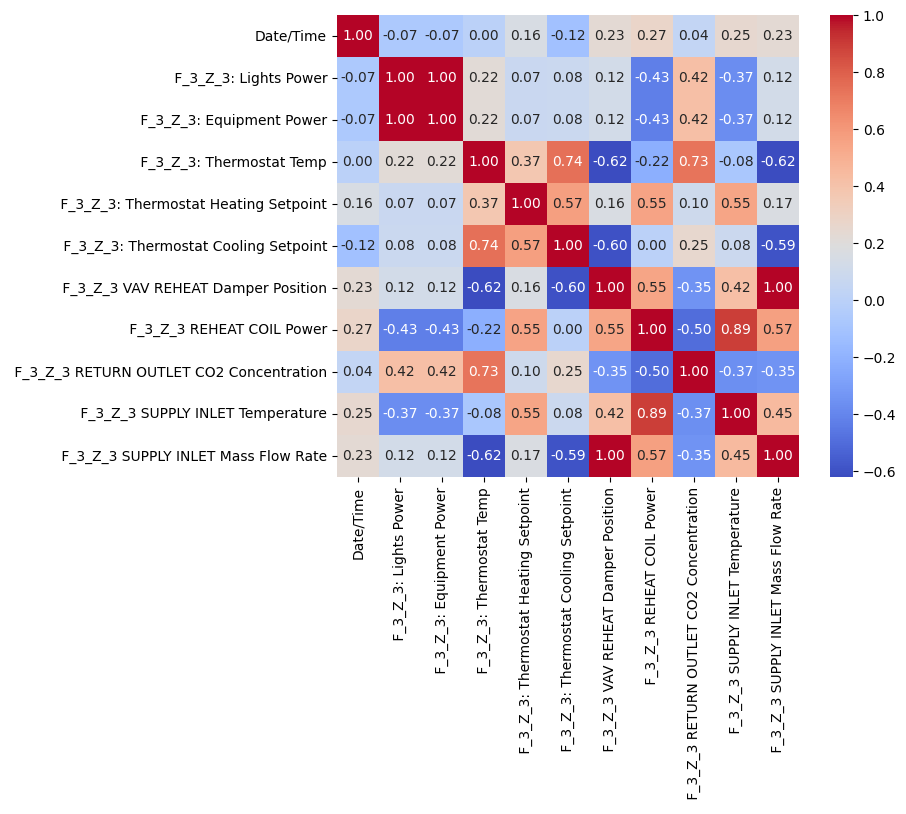

In [27]:
corr_matrix = df.corr()

# Визуализация (тепловая карта)
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.show()

Заметим:

* `Lights Power` и `Equipment Power`: идеальная коррелляция (это один признак)
* `Mass Flow Rate` и `Damper Position`: идеальная коррелляция (это один признак)
* `REHEAT COIL Power` c `Damper` и `Supply Temp` : высокая коррелляция (0.89)

Таким образом, стоит точно выбросить признаки `Equipment Power` (дубликат) и `Damper Position` (дубликат).
Дополнительно для лучшей визуализации следует выкинуть признак `REHEAT COIL Power` (избыточен из-за высокой коррелляции с существующими признаками)

---

__Итоговый вывод:__ на основе анализа предлагаю выкинуть 3 признака:

* __`Equipment Power`:__ дубликат
* __`Mass Flow Rate`:__ дубликат
* __`REHEAT COIL Power`:__ высокая коррелляция с другими признаками

In [28]:
features_to_drop = [
    ' F_3_Z_3: Equipment Power', 
    ' F_3_Z_3 SUPPLY INLET Mass Flow Rate', 
    ' F_3_Z_3 REHEAT COIL Power'
]

df = df.drop(columns=features_to_drop)

# сохраним на будущее
FEATURES_FILTERED = list(set(FEATURES) - set(features_to_drop))
FEATURES_FILTERED

[' F_3_Z_3: Lights Power',
 ' F_3_Z_3: Thermostat Temp',
 ' F_3_Z_3 VAV REHEAT Damper Position',
 ' F_3_Z_3 RETURN OUTLET CO2 Concentration',
 ' F_3_Z_3: Thermostat Heating Setpoint',
 ' F_3_Z_3 SUPPLY INLET Temperature',
 ' F_3_Z_3: Thermostat Cooling Setpoint']

# Глубокий анализ (дополнительно)

Предлагаю чуть глубже посмотреть на признаки, чтобы лучше понимать, чего ожидать при дальнейшей визацлизации с помощью лиц

In [29]:
def plot_feature_histogram(ax, df, feature, bins=30, y_scale='linear'):
    n_bins = min(bins, df[feature].nunique())
    
    ax.set_yscale(y_scale)
    ax.hist(df[feature].dropna(), bins=n_bins, edgecolor='black', alpha=0.7)
    ax.set_title(feature, fontsize=12)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.grid(True, linestyle='--', alpha=0.3)

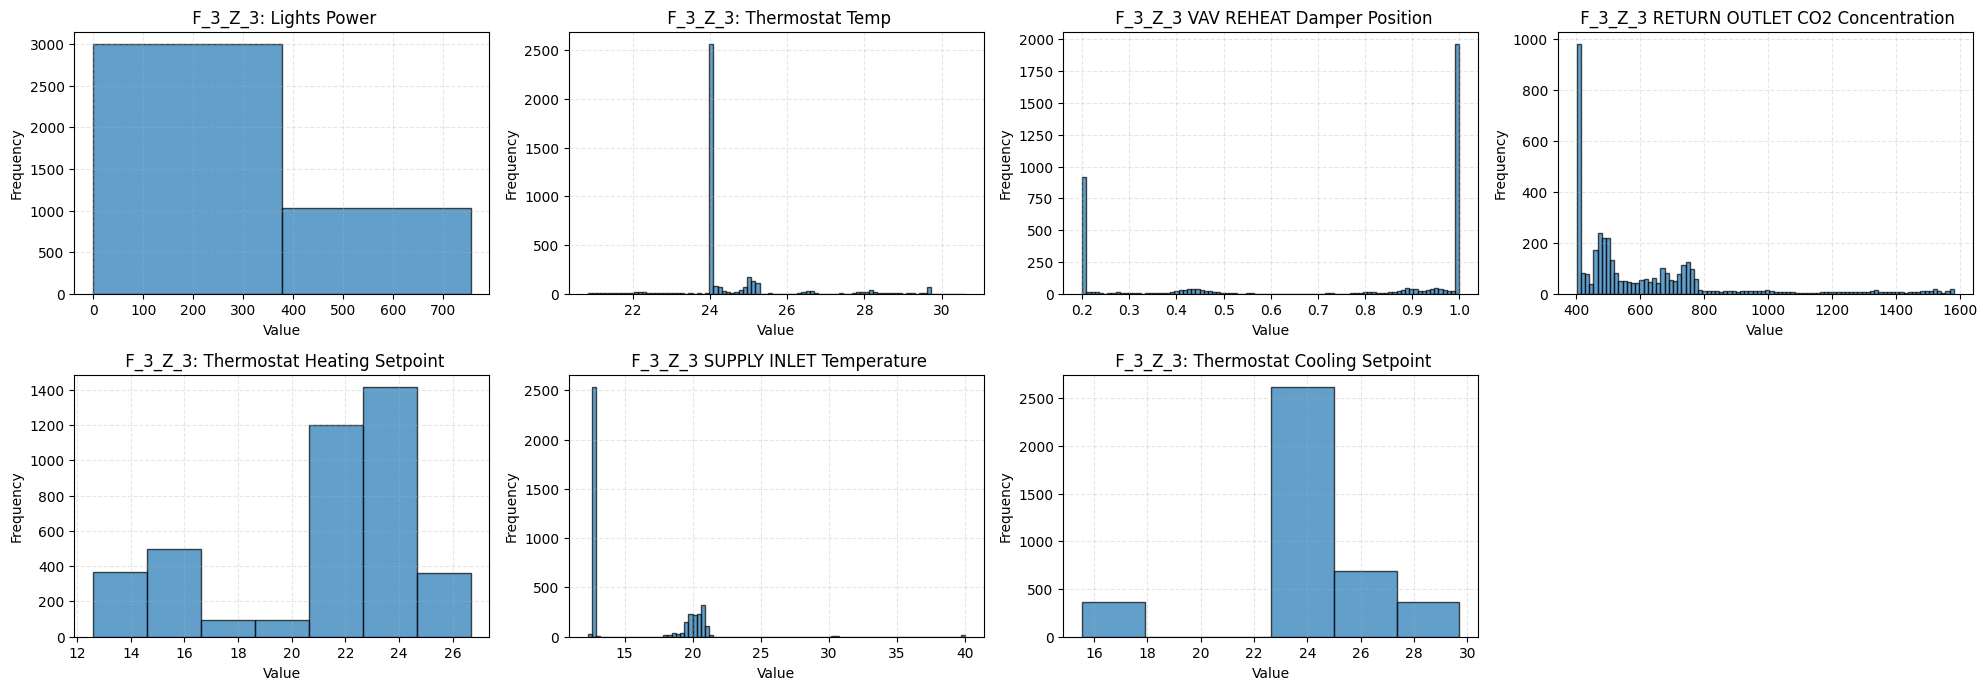

In [30]:
n_features = len(FEATURES_FILTERED)

fig, axes = plt.subplots(3, 4, figsize=(20, 10))
axes = axes.flatten() if n_features > 1 else [axes]

for idx, feature in enumerate(FEATURES_FILTERED):
    plot_feature_histogram(axes[idx], df, feature, bins=90, y_scale='linear')
for idx in range(n_features, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

По графикам распределений можно выделить следующие паттерны:

* __Признаки с бимодальным распределением (режимы ВКЛ/ВЫКЛ):__ эти признаки работают в дискретных режимах. Для визуализации это менее информативно — лица будут меняться скачкообразно, а не плавно.
    * `Lights Power`: свет либо выключен, либо на полной мощности
    * `Damper Position`: заслонка либо почти закрыта, либо полностью открыта
    * `SUPPLY INLET Temperature`: нормальная подача / аномальный перегрев

* __Признаки с концентрацией вокруг одного значения:__ эти признаки мало варьируются в норме. Аномалии будут видны, но в 80% дней лица будут выглядеть одинаково.
    * `Thermostat Temp` (низкая дисперсия — мало информации для визуализации)
    * `Thermostat Cooling Setpoint` (большинство значений в узком диапазоне)

* __Наиболее информативные признаки (для визуализации):__
    * `Heating Setpoint` (показывает разные стратегии отопления)
    * `CO2 Concentration` (четко виден аномальный хвост)
    * `Supply Inlet Temperature` (аномалия как отдельный пик)

In [31]:
def plot_time_series_daily(df, date_col='Date/Time', figsize=(15, 20), show_ylabels=True):
    # Сортировка по дате
    df = df.sort_values(by=date_col).copy()
    
    x = df[date_col]
    features = [col for col in df.columns if col != date_col]
    n_features = len(features)

    fig, axes = plt.subplots(n_features, 1, figsize=figsize, sharex=True)
    if n_features == 1:
        axes = [axes]

    for i, feature in enumerate(features):
        ax = axes[i]
        # Плотный график (линии соединяют все точки)
        ax.plot(x, df[feature], linewidth=0.8, label=feature)
        if show_ylabels:
            ax.set_ylabel(feature)
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.legend(loc='upper right')

    # Настройка оси X: отметки по дням
    ax_last = axes[-1]
    ax_last.set_xlabel('Date')
    
    # Форматирование дат: день-месяц
    ax_last.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax_last.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    
    # Поворот подписей для читаемости
    plt.setp(ax_last.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

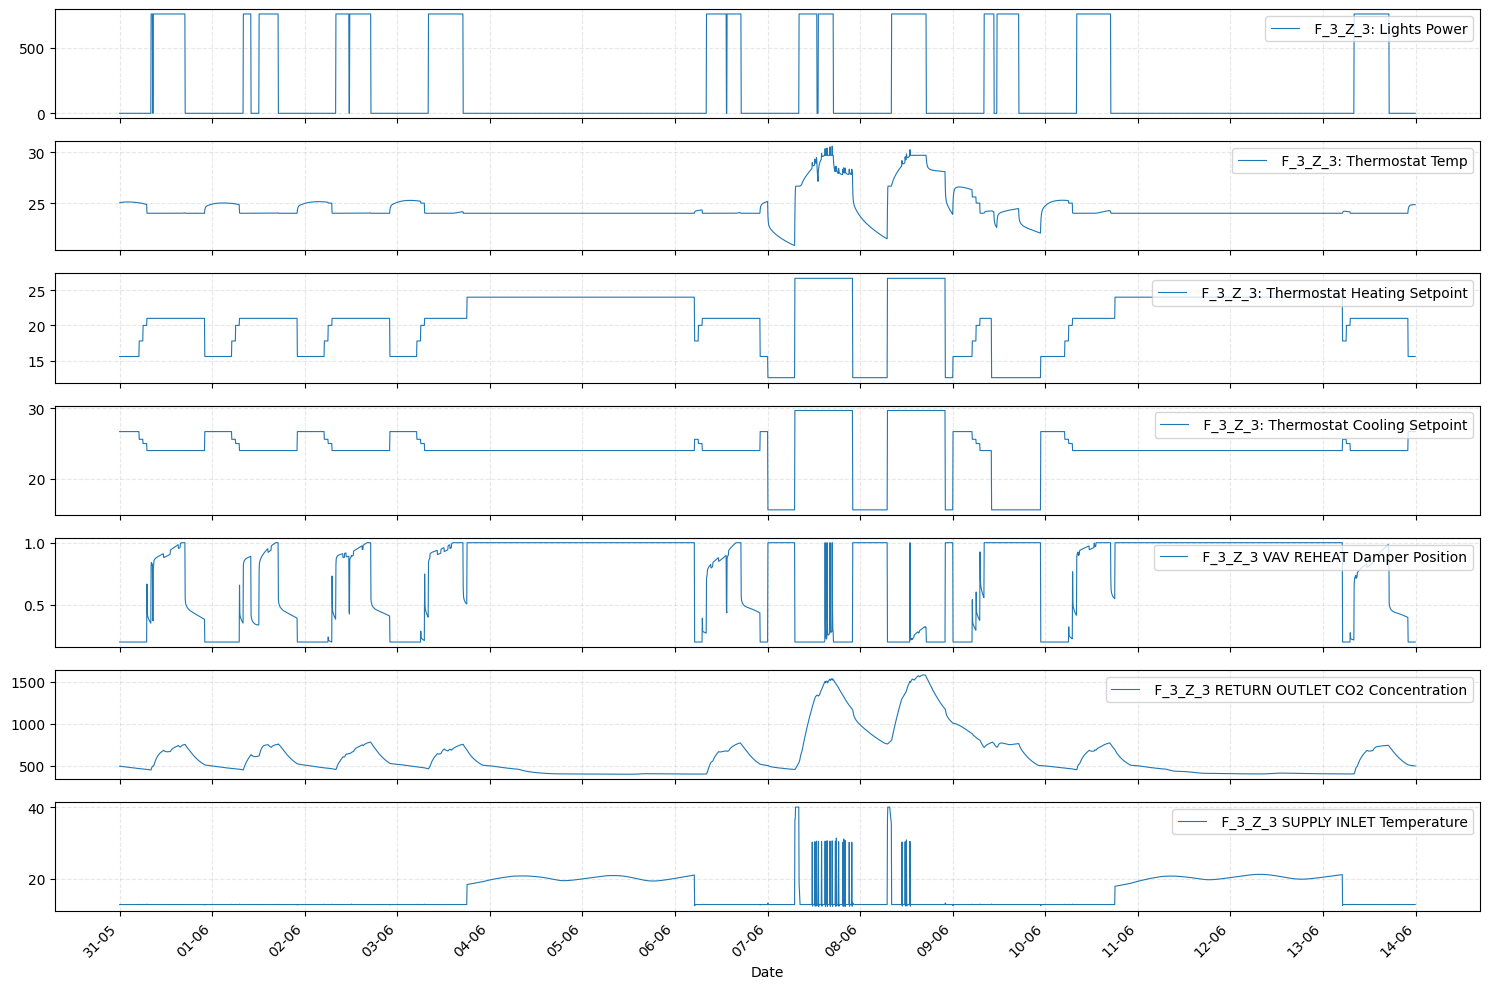

In [33]:
plot_time_series_daily(df, figsize=(15, 10), show_ylabels=False)

На основе построенных графиков выявлена чёткая аномальная зона: __7-9 июня__.

В общем случае все показатели ведут себя нормально. Например:
* __`Lights Power`:__ норма; чёткий режим "вкл/выкл" (будние дни, рабочие часы)
* __`Thermostat Temp`:__ 24-25°C (стабильно)
* __`Thermostat Heating Setpoint:`:__ плавные ступенчатые изменения

и т.д.

Однако в интервале __7-9 июня__ наблюдается аномалия у большинства признаков. Например:

* __`Thermostat Temp`:__ 25-30°C (скачки)
* __`Heating & Cooling Setpoint`:__ хаотичные переключения, противоречивые команды
* __`Damper Position`:__ частые резкие переключения, "дребезг"

и т.д

# Обработка данных

In [ ]:
# отбросим столбец с датой - он больше не нужен
df = df.drop(columns=['Date/Time'])

# теперь df.columns == FEATURES_FILETERED

In [45]:
# нормализация
minmax_scaler = MinMaxScaler(feature_range=(0, 1))

df_scaled = pd.DataFrame(
    minmax_scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

In [46]:
df_scaled.describe()

,F_3_Z_3: Lights Power,F_3_Z_3: Thermostat Temp,F_3_Z_3: Thermostat Heating Setpoint,F_3_Z_3: Thermostat Cooling Setpoint,F_3_Z_3 VAV REHEAT Damper Position,F_3_Z_3 RETURN OUTLET CO2 Concentration,F_3_Z_3 SUPPLY INLET Temperature
count,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000,4032.000000
mean,0.256448,0.374231,0.599014,0.606075,0.648877,0.180490,0.121326
std,0.436726,0.148687,0.287293,0.227910,0.433524,0.223149,0.149411
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.324247,0.525942,0.596888,0.103250,0.013126,0.018739
50%,0.000000,0.324257,0.597015,0.596888,0.962813,0.088399,0.018786
75%,1.000000,0.371376,0.810235,0.667610,1.000000,0.265764,0.274997
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [47]:
# стандартизация
zscore_scaler = StandardScaler()

df_scaled = pd.DataFrame(
    zscore_scaler.fit_transform(df_scaled),
    columns=df.columns,
    index=df.index
)

In [48]:
df_scaled.describe()

,F_3_Z_3: Lights Power,F_3_Z_3: Thermostat Temp,F_3_Z_3: Thermostat Heating Setpoint,F_3_Z_3: Thermostat Cooling Setpoint,F_3_Z_3 VAV REHEAT Damper Position,F_3_Z_3 RETURN OUTLET CO2 Concentration,F_3_Z_3 SUPPLY INLET Temperature
count,4.032000e+03,4.032000e+03,4.032000e+03,4.032000e+03,4032.000000,4.032000e+03,4.032000e+03
mean,4.229421e-17,-2.819614e-16,-6.485112e-16,9.516197e-16,0.000000,2.819614e-17,-9.868649e-17
std,1.000124e+00,1.000124e+00,1.000124e+00,1.000124e+00,1.000124,1.000124e+00,1.000124e+00
min,-5.872790e-01,-2.517213e+00,-2.085289e+00,-2.659599e+00,-1.496935,-8.089316e-01,-8.121292e-01
25%,-5.872790e-01,-3.362104e-01,-2.543789e-01,-4.031213e-02,-1.258741,-7.501040e-01,-6.866949e-01
50%,-5.872790e-01,-3.361416e-01,-6.958694e-03,-4.031213e-02,0.724238,-4.127411e-01,-6.863810e-01
75%,1.702768e+00,-1.919860e-02,7.353021e-01,2.700299e-01,0.810028,3.821843e-01,1.028638e+00
max,1.702768e+00,4.209157e+00,1.395914e+00,1.728637e+00,0.810028,3.672931e+00,5.881650e+00


# Визуализация лиц

На основе оставшихся признаков и их анализа (в т.ч. глубокого) предлагаю следующую схему визуализации:

- **Левый глаз (размер):** `Thermostat Heating Setpoint`  
  Симметричная пара с `Thermostat Cooling Setpoint` для выявления конфликта и аномалий.

- **Правый глаз (размер):** `Thermostat Cooling Setpoint`  
  Симметричная пара с `Thermostat Heating Setpoint` для выявления конфликта и аномалий.

- **Левая бровь (наклон):** `Thermostat Temp`
  Сильная корреляция с `CO2 Concentration`; одна из наиболее воспринимаемых черт (Morris et al., 2000).

- **Правая бровь (наклон):**: `CO2 Concentration`  
  Сильная корреляция с `Thermostat Temp`; ключевой показатель качества воздуха.

- **Рот (кривизна):** `VAV REHEAT Damper Position`  
  управляет потоком воздуха — второстепенная черта.

- **Цвет лица:** `SUPPLY INLET Temperature`  
  Аномальный перегрев (до 40°C) = «болезненный» цвет; четко видна аномалия 7-9 июня.

- **Волосы (длина/густота):** `Lights Power`  
  Режим работы освещения; второстепенный параметр → менее заметная черта.

Таким образом, черты лица были назначены соответствующим признакам с учетом их коррелляций, а также физического смысла:

- Размер глаз и наклон бровей имеют самую высокую точность восприятия - поэтому на эти черты назначены наиболее важные для обнаружения аномалий признаки:
  * Глаза: `Heating/Cooling Setpoint` (команды системе)
  * Брови: `Thermostat Temp` + `CO2 Concentration` (фактическое состояние)

- Выполнен учет корреляций:
   - `Heating` VS `Cooling Setpoint`: r=0.57 (умеренная) → симметричные глаза
   - `Thermostat Temp` VS `CO2`: r=0.73 (сильная) → симметричные брови
  Таким образом, в норме - симметричное лицо, а в аномалии - асимметрия из-за нарушения корреляций

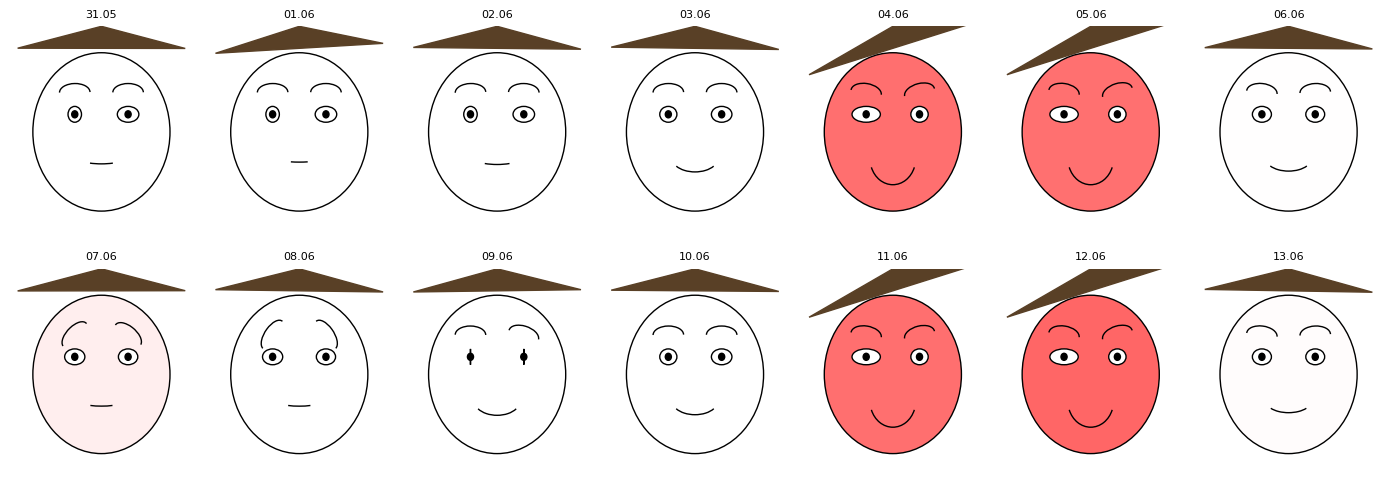

In [75]:
# --- колонки ---
heat = df_scaled[' F_3_Z_3: Thermostat Heating Setpoint'].values
cool = df_scaled[' F_3_Z_3: Thermostat Cooling Setpoint'].values
temp = df_scaled[' F_3_Z_3: Thermostat Temp'].values
co2  = df_scaled[' F_3_Z_3 RETURN OUTLET CO2 Concentration'].values
damper = df_scaled[' F_3_Z_3 VAV REHEAT Damper Position'].values
supply = df_scaled[' F_3_Z_3 SUPPLY INLET Temperature'].values
light = df_scaled[' F_3_Z_3: Lights Power'].values

# --- делим на 14 дней ---
def split_days(x):
    return np.array([d.mean() for d in np.array_split(x, 14)])

heat = split_days(heat)
cool = split_days(cool)
temp = split_days(temp)
co2  = split_days(co2)
damper = split_days(damper)
supply = split_days(supply)
light = split_days(light)

# --- база (норма) ---
heat0 = np.median(heat)
cool0 = np.median(cool)
temp0 = np.median(temp)
co20  = np.median(co2)
damper0 = np.median(damper)
supply0 = np.median(supply)
light0 = np.median(light)

# --- отклонения ---
d_heat = heat - heat0
d_cool = cool - cool0
d_temp = temp - temp0
d_co2  = co2 - co20
d_damper = damper - damper0
d_supply = supply - supply0
d_light = light - light0

# нормализация отклонений
def norm(x):
    m = np.max(np.abs(x))
    return x / m if m != 0 else x

d_heat = norm(d_heat)
d_cool = norm(d_cool)
d_temp = norm(d_temp)
d_co2  = norm(d_co2)
d_damper = norm(d_damper)
d_supply = norm(d_supply)
d_light = norm(d_light)

# --- рисование лица ---
def draw_face(ax, eh, ec, bt, bc, m, col, h):
    ax.set_xlim(-1.2,1.2)
    ax.set_ylim(-1.2,1.2)
    ax.axis('off')

    # волосы (простые, с перекосом)
    y_base = 0.95
    tilt = h * 0.3
    x = [-1.1, 1.1, 0]
    y = [y_base+tilt, y_base-tilt, 1.2]
    ax.fill(x, y, color=(0.35,0.25,0.15), zorder=0)

    # цвет лица (аномалия температуры)
    c = np.clip(col, -1, 1)
    face_color = (1, 1-0.6*max(0,c), 1-0.6*max(0,c))

    ax.add_patch(Circle((0,0), 0.9, facecolor=face_color, edgecolor='k', zorder=1))

    # глаза (асимметрия = конфликт)
    ax.add_patch(Ellipse((-0.35,0.2), 0.25*(1+eh), 0.18, facecolor='white', edgecolor='k'))
    ax.add_patch(Ellipse((0.35,0.2), 0.25*(1+ec), 0.18, facecolor='white', edgecolor='k'))

    ax.add_patch(Circle((-0.35,0.2), 0.04, color='k'))
    ax.add_patch(Circle((0.35,0.2), 0.04, color='k'))

    # брови (темп + CO2)
    ax.add_patch(Arc((-0.35,0.45), 0.4, 0.2, angle=bt*50, theta1=0, theta2=180))
    ax.add_patch(Arc((0.35,0.45), 0.4, 0.2, angle=-bc*50, theta1=0, theta2=180))

    # рот (damper)
    ax.add_patch(Arc((0,-0.3), 0.6, 0.3*(1+m), theta1=200, theta2=340))

# --- даты ---
dates = ["31.05"] + [f"{d:02d}.06" for d in range(1,14)]

# --- построение ---
fig, axes = plt.subplots(2,7, figsize=(14,5))
axes = axes.flatten()

for i in range(14):
    draw_face(
        axes[i],
        d_heat[i], d_cool[i],
        d_temp[i], d_co2[i],
        d_damper[i],
        d_supply[i],
        d_light[i]
    )
    axes[i].set_title(dates[i], fontsize=8)

plt.tight_layout()
plt.show()

In [78]:
for col in df_scaled.columns:
    print(col)

 F_3_Z_3: Lights Power
 F_3_Z_3: Thermostat Temp
 F_3_Z_3: Thermostat Heating Setpoint
 F_3_Z_3: Thermostat Cooling Setpoint
 F_3_Z_3 VAV REHEAT Damper Position
 F_3_Z_3 RETURN OUTLET CO2 Concentration
 F_3_Z_3 SUPPLY INLET Temperature
